# Demand forecasting & stock planning
Weekly SKU demand for a UK wholesaler (UCI Online Retail II). Goal: forecast 1–4 weeks ahead and turn forecasts into stock levels.

In [1]:
import sys; sys.path.insert(0, 'src')
import pandas as pd, data, forecast as f, inventory as inv
panel = data.load_panel()
panel.head()

,StockCode,Week,units,revenue,price,orders,customers,Description
0,22423,2009-12-07,0.0,0.0,12.75,0.0,0.0,REGENCY CAKESTAND 3 TIER
1,22423,2009-12-14,0.0,0.0,12.75,0.0,0.0,REGENCY CAKESTAND 3 TIER
2,22423,2009-12-21,0.0,0.0,12.75,0.0,0.0,REGENCY CAKESTAND 3 TIER
3,22423,2009-12-28,0.0,0.0,12.75,0.0,0.0,REGENCY CAKESTAND 3 TIER
4,22423,2010-01-04,0.0,0.0,12.75,0.0,0.0,REGENCY CAKESTAND 3 TIER


## Demand is lumpy
Many SKU-weeks are zero and a few are huge bulk orders, which is why simple averages are hard to beat.

Matplotlib is building the font cache; this may take a moment.


share of zero SKU-weeks: 0.13346153846153846


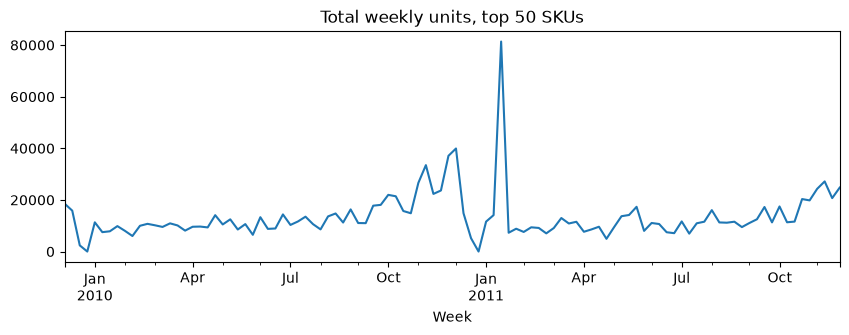

In [2]:
panel.groupby('Week').units.sum().plot(figsize=(10,3), title='Total weekly units, top 50 SKUs');
print('share of zero SKU-weeks:', (panel.units==0).mean())

## Rolling-origin backtest
8 forecast origins, 4 horizons. Training rows only use targets observed before each origin.

In [3]:
feat = f.make_features(panel)
preds = f.predict_folds(feat)
s = f.score(preds)
s.pivot_table(index='h', columns='model', values='wape').round(3)

model,gbm,moving_avg_4,seasonal_naive
h,,,
1,0.530,0.634,0.949
2,0.533,0.584,0.847
3,0.528,0.550,0.831
4,0.558,0.612,0.796


In [4]:
s.groupby('model')[['wape','bias']].mean().round(3)

,wape,bias
model,,
gbm,0.537,-0.112
moving_avg_4,0.595,-0.028
seasonal_naive,0.856,0.227


## From forecast to stock
Lead time 2 weeks. Compare moving average + safety stock against the 90th-percentile model forecast **at the same fill rate**.

In [5]:
p = inv.policy_levels(preds)
q90 = inv.evaluate(p, ['gbm_q90_stock'])
z, q = inv.match_fill_rate(p, q90.fill_rate[0])
print('matched z =', round(z,2))
inv.evaluate(q, ['moving_avg_matched','gbm_q90_stock']).round(3)

matched z = 1.64


,policy,fill_rate,overstock_units,overstock_pct_of_demand,sku_weeks_stocked_out
0,moving_avg_matched,0.888,102266.796,0.986,0.168
1,gbm_q90_stock,0.888,88421.919,0.853,0.150
